<a href="https://colab.research.google.com/github/jaywong8/Detection-of-Atrial-Fibrillation-Termination/blob/main/Patient_Split_and_Sampling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

A ran version of this can be found at the bottom of "parsing postiive segments"

In [1]:
!pip -q install wfdb pandas numpy scipy scikit-learn matplotlib

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:

# ============================================================
# ICENTIA11K AFIB INTERVAL-END PREDICTION
# Stage 1: Reproducible patient split and window sampling
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

# ---------- Paths ----------
AUDIT_DIR = Path(
    "/content/drive/MyDrive/icentia11k_afib_audit"
)
EPISODE_FILE = AUDIT_DIR / "afib_episode_audit.csv"

OUTPUT_DIR = AUDIT_DIR / "pilot_10s_30s"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------- Prediction task ----------
INPUT_SECONDS = 10
HORIZON_SECONDS = 30
STRIDE_SECONDS = 10
SAMPLING_RATE_HZ = 250

# ---------- Patient split ----------
TRAIN_FRACTION = 0.70
VALIDATION_FRACTION = 0.15
TEST_FRACTION = 0.15
RANDOM_SEED = 42

# ---------- Pilot sampling controls ----------
# Training: cap the number of selected windows per interval
# and per patient to reduce domination by long intervals
# and high-volume patients.
MAX_WINDOWS_PER_EPISODE = 3
MAX_WINDOWS_PER_PATIENT = 100

# Small natural-distribution samples for initial validation/test
# feature extraction. Increase later if computationally feasible.
VALIDATION_SAMPLE_N = 3000
TEST_SAMPLE_N = 3000

print("Configuration loaded.")
print(f"Input: {INPUT_SECONDS} seconds")
print(f"Prediction horizon: {HORIZON_SECONDS} seconds")
print(f"Stride: {STRIDE_SECONDS} seconds")
print(f"Output folder: {OUTPUT_DIR}")


In [ ]:

# Load previously audited candidate AFib intervals.
episodes = pd.read_csv(EPISODE_FILE)

required_columns = {
    "patient", "record_stem", "start_sec",
    "end_sec", "duration_sec"
}

missing = required_columns - set(episodes.columns)
if missing:
    raise ValueError(f"Missing required columns: {missing}")

episodes = episodes.copy()

# Normalize identifiers for consistent grouping.
episodes["patient"] = episodes["patient"].astype(str)
episodes["record_stem"] = episodes["record_stem"].astype(str)

# Remove rows that cannot define a valid interval.
episodes = episodes.dropna(
    subset=["patient", "record_stem", "start_sec", "end_sec"]
)

episodes = episodes[
    (episodes["start_sec"] >= 0) &
    (episodes["end_sec"] > episodes["start_sec"])
].copy()

# Recalculate duration rather than trusting a possibly stale column.
episodes["duration_sec"] = (
    episodes["end_sec"] - episodes["start_sec"]
)

# An interval ID uniquely identifies a row in this audit file.
# It is an analysis key, NOT a model feature.
episodes = episodes.reset_index(drop=True)
episodes["episode_id"] = [
    f"episode_{i:06d}" for i in range(len(episodes))
]

print("Intervals:", len(episodes))
print("Patients:", episodes["patient"].nunique())
print("Records:", episodes["record_stem"].nunique())

display(
    episodes["duration_sec"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.99]
    ).to_frame("duration_seconds")
)


In [ ]:

# One row per patient. All records and intervals belonging to a
# patient stay in the same partition.
patients = np.array(sorted(episodes["patient"].unique()))

train_patients, remaining_patients = train_test_split(
    patients,
    train_size=TRAIN_FRACTION,
    random_state=RANDOM_SEED,
    shuffle=True
)

# Split the remaining patients into validation and test.
test_fraction_of_remaining = (
    TEST_FRACTION / (VALIDATION_FRACTION + TEST_FRACTION)
)

validation_patients, test_patients = train_test_split(
    remaining_patients,
    test_size=test_fraction_of_remaining,
    random_state=RANDOM_SEED,
    shuffle=True
)

patient_split = {
    **{p: "train" for p in train_patients},
    **{p: "validation" for p in validation_patients},
    **{p: "test" for p in test_patients},
}

episodes["partition"] = episodes["patient"].map(patient_split)

# Verify there is no patient leakage.
assert set(train_patients).isdisjoint(validation_patients)
assert set(train_patients).isdisjoint(test_patients)
assert set(validation_patients).isdisjoint(test_patients)

split_manifest = pd.DataFrame({
    "patient": list(patient_split.keys()),
    "partition": list(patient_split.values())
}).sort_values(["partition", "patient"])

split_manifest.to_csv(
    OUTPUT_DIR / "patient_split_manifest.csv",
    index=False
)

print(split_manifest.groupby("partition")["patient"].nunique())
print("Patient split saved.")


In [ ]:

def make_windows_for_episode(row):
    """
    Create candidate windows for one annotated interval.

    A window ends at prediction_time_sec.
    The 10-second input immediately precedes that time.

    Label:
        1 = interval ends within the next 30 seconds
        0 = interval continues beyond the next 30 seconds

    This predicts an annotated interval boundary, not verified
    clinical conversion to sinus rhythm.
    """
    start = float(row["start_sec"])
    end = float(row["end_sec"])

    # First prediction time after a complete input window.
    first_prediction_time = start + INPUT_SECONDS

    if first_prediction_time >= end:
        return []

    times = np.arange(
        first_prediction_time,
        end,
        STRIDE_SECONDS
    )

    rows = []

    for prediction_time in times:
        seconds_until_end = end - prediction_time

        # Exclude zero-time outcomes: the event is not in the future.
        if seconds_until_end <= 0:
            continue

        # Label based only on time remaining to this interval's end.
        label = int(seconds_until_end <= HORIZON_SECONDS)

        rows.append({
            "patient": row["patient"],
            "record_stem": row["record_stem"],
            "episode_id": row["episode_id"],
            "episode_start_sec": start,
            "episode_end_sec": end,
            "prediction_time_sec": float(prediction_time),
            "input_start_sec": float(
                prediction_time - INPUT_SECONDS
            ),
            "seconds_until_annotated_end": float(seconds_until_end),
            "label": label,
            "partition": row["partition"],
        })

    return rows


# Generate metadata for every eligible candidate window.
window_rows = []

for row in episodes.to_dict("records"):
    window_rows.extend(make_windows_for_episode(row))

windows = pd.DataFrame(window_rows)

if windows.empty:
    raise ValueError("No eligible windows were generated.")

# Stable, unique ID for reproducibility and auditing.
windows = windows.reset_index(drop=True)
windows["window_id"] = [
    f"window_{i:08d}" for i in range(len(windows))
]

print("Eligible windows:", len(windows))
print("Positive rate:", round(windows["label"].mean(), 4))
print("Patients represented:", windows["patient"].nunique())
print("Intervals represented:", windows["episode_id"].nunique())


In [ ]:

def sample_training_windows(
    train_windows,
    max_per_episode=3,
    max_per_patient=100,
    seed=42
):
    """
    Pilot training sampler.

    1. Shuffle patients.
    2. Shuffle intervals within each patient.
    3. Select up to max_per_episode windows per interval.
    4. Stop at max_per_patient windows per patient.

    Random selection is reproducible for a fixed input table,
    settings, and seed.
    """
    rng = np.random.default_rng(seed)
    selected_parts = []

    for patient in rng.permutation(
        train_windows["patient"].unique()
    ):
        patient_rows = train_windows[
            train_windows["patient"] == patient
        ]

        episode_ids = rng.permutation(
            patient_rows["episode_id"].unique()
        )

        patient_selected = []
        patient_count = 0

        for episode_id in episode_ids:
            episode_rows = patient_rows[
                patient_rows["episode_id"] == episode_id
            ]

            remaining_capacity = (
                max_per_patient - patient_count
            )

            if remaining_capacity <= 0:
                break

            n_to_take = min(
                max_per_episode,
                remaining_capacity,
                len(episode_rows)
            )

            # Uniform sample within this interval.
            chosen_indices = rng.choice(
                episode_rows.index.to_numpy(),
                size=n_to_take,
                replace=False
            )

            chosen = episode_rows.loc[chosen_indices]
            patient_selected.append(chosen)
            patient_count += len(chosen)

        if patient_selected:
            selected_parts.extend(patient_selected)

    if not selected_parts:
        return train_windows.iloc[0:0].copy()

    return (
        pd.concat(selected_parts)
        .sample(frac=1, random_state=seed)
        .reset_index(drop=True)
    )


train_candidates = windows[
    windows["partition"] == "train"
].copy()

train_sample = sample_training_windows(
    train_candidates,
    max_per_episode=MAX_WINDOWS_PER_EPISODE,
    max_per_patient=MAX_WINDOWS_PER_PATIENT,
    seed=RANDOM_SEED
)

print("Training candidate windows:", len(train_candidates))
print("Selected training windows:", len(train_sample))
print("Training positive rate:", round(train_sample["label"].mean(), 4))


In [ ]:

def natural_window_sample(df, target_n, seed):
    """Uniformly sample candidate windows without class balancing."""
    if len(df) <= target_n:
        return df.copy().reset_index(drop=True)

    return df.sample(
        n=target_n,
        replace=False,
        random_state=seed
    ).reset_index(drop=True)


validation_candidates = windows[
    windows["partition"] == "validation"
].copy()

test_candidates = windows[
    windows["partition"] == "test"
].copy()

validation_sample = natural_window_sample(
    validation_candidates,
    VALIDATION_SAMPLE_N,
    RANDOM_SEED + 1
)

test_sample = natural_window_sample(
    test_candidates,
    TEST_SAMPLE_N,
    RANDOM_SEED + 2
)

print("Validation candidates:", len(validation_candidates))
print("Validation sample:", len(validation_sample))
print("Test candidates:", len(test_candidates))
print("Test sample:", len(test_sample))


In [ ]:

sampled = pd.concat(
    [train_sample, validation_sample, test_sample],
    ignore_index=True
)

def summarize_partition(name, df):
    if df.empty:
        return {
            "partition": name,
            "windows": 0,
            "patients": 0,
            "intervals": 0,
            "positive_windows": 0,
            "negative_windows": 0,
            "positive_rate": np.nan,
            "largest_patient_share": np.nan,
            "largest_interval_share": np.nan,
        }

    patient_shares = df["patient"].value_counts(normalize=True)
    interval_shares = df["episode_id"].value_counts(normalize=True)

    return {
        "partition": name,
        "windows": len(df),
        "patients": df["patient"].nunique(),
        "intervals": df["episode_id"].nunique(),
        "positive_windows": int((df["label"] == 1).sum()),
        "negative_windows": int((df["label"] == 0).sum()),
        "positive_rate": df["label"].mean(),
        "largest_patient_share": patient_shares.max(),
        "largest_interval_share": interval_shares.max(),
    }


summary = pd.DataFrame([
    summarize_partition("train", train_sample),
    summarize_partition("validation", validation_sample),
    summarize_partition("test", test_sample),
])

display(summary)

# Inspect patient contribution in training.
train_patient_counts = (
    train_sample.groupby("patient")
    .size()
    .rename("selected_windows")
    .reset_index()
    .sort_values("selected_windows", ascending=False)
)

display(train_patient_counts.head(15))

# Inspect interval contribution in training.
train_episode_counts = (
    train_sample.groupby(["patient", "episode_id"])
    .size()
    .rename("selected_windows")
    .reset_index()
    .sort_values("selected_windows", ascending=False)
)

display(train_episode_counts.head(15))

# Check label availability in every partition.
for name, df in [
    ("train", train_sample),
    ("validation", validation_sample),
    ("test", test_sample)
]:
    print(
        name,
        "labels:",
        df["label"].value_counts().sort_index().to_dict()
    )


In [ ]:

# ============================================================
# SAMPLING STRATEGY COMPARISON
# Metadata only — no ECG signals are loaded.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

AUDIT_DIR = Path("/content/drive/MyDrive/icentia11k_afib_audit")
OUTPUT_DIR = AUDIT_DIR / "pilot_10s_30s"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

WINDOW_FILE = OUTPUT_DIR / "candidate_window_index.csv"
SPLIT_FILE = OUTPUT_DIR / "patient_split_manifest.csv"

SEED = 42

# Compare strategies at the same approximate training sample size.
TARGET_TRAIN_WINDOWS = 8728

# Adjustable caps for the two interval-balanced strategies.
MAX_PER_EPISODE = 3
MAX_PER_PATIENT = 100

windows = pd.read_csv(WINDOW_FILE)
split_manifest = pd.read_csv(SPLIT_FILE)

required = {
    "patient", "episode_id", "label",
    "prediction_time_sec", "partition"
}
missing = required - set(windows.columns)
if missing:
    raise ValueError(f"Missing columns in window index: {missing}")

# Reuse the existing split manifest as the source of truth.
windows["patient"] = windows["patient"].astype(str)
split_manifest["patient"] = split_manifest["patient"].astype(str)

partition_lookup = dict(zip(
    split_manifest["patient"],
    split_manifest["partition"]
))

windows["partition"] = windows["patient"].map(partition_lookup)

if windows["partition"].isna().any():
    raise ValueError("Some window patients are missing from the split manifest.")

train = windows[windows["partition"] == "train"].copy()

print("Training candidate windows:", len(train))
print("Training patients:", train["patient"].nunique())
print("Training intervals:", train["episode_id"].nunique())
print("Natural training positive rate:", round(train["label"].mean(), 4))


# ------------------------------------------------------------
# Strategy A: natural window sampling
# Each eligible training window has equal selection probability.
# ------------------------------------------------------------
def sample_natural_windows(df, target_n, seed):
    n = min(target_n, len(df))
    return df.sample(n=n, replace=False, random_state=seed).copy()


# ------------------------------------------------------------
# Strategy B/C: interval-first sampling
# Select up to a fixed number of windows per interval.
# Optionally cap each patient's total contribution.
#
# Intervals and patients are visited in random order.
# This is a sampling comparison, not class balancing.
# ------------------------------------------------------------
def sample_interval_first(
    df,
    target_n,
    max_per_episode,
    max_per_patient=None,
    seed=42
):
    rng = np.random.default_rng(seed)
    selected = []
    total_selected = 0

    patient_ids = rng.permutation(df["patient"].unique())

    for patient in patient_ids:
        if total_selected >= target_n:
            break

        patient_df = df[df["patient"] == patient]
        episode_ids = rng.permutation(
            patient_df["episode_id"].unique()
        )

        patient_count = 0

        for episode_id in episode_ids:
            if total_selected >= target_n:
                break

            if (
                max_per_patient is not None
                and patient_count >= max_per_patient
            ):
                break

            episode_df = patient_df[
                patient_df["episode_id"] == episode_id
            ]

            episode_limit = min(
                max_per_episode,
                len(episode_df)
            )

            if max_per_patient is not None:
                remaining_patient_capacity = (
                    max_per_patient - patient_count
                )
                episode_limit = min(
                    episode_limit,
                    remaining_patient_capacity
                )

            remaining_target = target_n - total_selected
            n_take = min(episode_limit, remaining_target)

            if n_take <= 0:
                continue

            chosen_indices = rng.choice(
                episode_df.index.to_numpy(),
                size=n_take,
                replace=False
            )

            selected.append(episode_df.loc[chosen_indices])
            total_selected += n_take
            patient_count += n_take

    if not selected:
        return df.iloc[0:0].copy()

    result = pd.concat(selected, ignore_index=True)

    # Do not silently claim the requested sample size was achieved.
    if len(result) < target_n:
        print(
            f"NOTE: requested {target_n:,} windows; "
            f"caps allowed only {len(result):,}."
        )

    return result


# A. Natural window-weighted sample.
natural = sample_natural_windows(
    train, TARGET_TRAIN_WINDOWS, SEED
)
natural["strategy"] = "natural_windows"

# B. Interval cap, without a patient cap.
equal_interval = sample_interval_first(
    train,
    target_n=TARGET_TRAIN_WINDOWS,
    max_per_episode=MAX_PER_EPISODE,
    max_per_patient=None,
    seed=SEED
)
equal_interval["strategy"] = "equal_interval_cap"

# C. Interval cap plus patient cap.
equal_interval_patient_cap = sample_interval_first(
    train,
    target_n=TARGET_TRAIN_WINDOWS,
    max_per_episode=MAX_PER_EPISODE,
    max_per_patient=MAX_PER_PATIENT,
    seed=SEED
)
equal_interval_patient_cap["strategy"] = "interval_and_patient_caps"


# ------------------------------------------------------------
# Summary metrics
# ------------------------------------------------------------
def summarize_strategy(name, df):
    if df.empty:
        return {
            "strategy": name,
            "windows": 0,
            "patients": 0,
            "intervals": 0,
            "positive_windows": 0,
            "negative_windows": 0,
            "positive_rate": np.nan,
            "largest_patient_share": np.nan,
            "largest_interval_share": np.nan,
            "median_windows_per_patient": np.nan,
            "median_windows_per_interval": np.nan,
        }

    patient_counts = df.groupby("patient").size()
    interval_counts = df.groupby("episode_id").size()

    return {
        "strategy": name,
        "windows": len(df),
        "patients": df["patient"].nunique(),
        "intervals": df["episode_id"].nunique(),
        "positive_windows": int((df["label"] == 1).sum()),
        "negative_windows": int((df["label"] == 0).sum()),
        "positive_rate": df["label"].mean(),
        "largest_patient_share": patient_counts.max() / len(df),
        "largest_interval_share": interval_counts.max() / len(df),
        "median_windows_per_patient": patient_counts.median(),
        "median_windows_per_interval": interval_counts.median(),
    }


comparison = pd.DataFrame([
    summarize_strategy("natural_windows", natural),
    summarize_strategy("equal_interval_cap", equal_interval),
    summarize_strategy(
        "interval_and_patient_caps",
        equal_interval_patient_cap
    ),
])

display(comparison.round(4))

# Save each sample and the comparison for team review.
natural.to_csv(OUTPUT_DIR / "comparison_natural.csv", index=False)
equal_interval.to_csv(
    OUTPUT_DIR / "comparison_equal_interval.csv", index=False
)
equal_interval_patient_cap.to_csv(
    OUTPUT_DIR / "comparison_interval_patient_caps.csv",
    index=False
)
comparison.to_csv(
    OUTPUT_DIR / "sampling_strategy_comparison.csv",
    index=False
)

print("Saved comparison files to:", OUTPUT_DIR)


In [ ]:

# Save the selected window manifests.
train_sample.to_csv(
    OUTPUT_DIR / "train_windows.csv", index=False
)
validation_sample.to_csv(
    OUTPUT_DIR / "validation_windows.csv", index=False
)
test_sample.to_csv(
    OUTPUT_DIR / "test_windows.csv", index=False
)

# Save the complete candidate-window metadata for reproducibility.
# This contains timestamps and labels, not ECG waveform samples.
windows.to_csv(
    OUTPUT_DIR / "candidate_window_index.csv", index=False
)

summary.to_csv(
    OUTPUT_DIR / "partition_summary.csv", index=False
)

config = {
    "input_seconds": INPUT_SECONDS,
    "prediction_horizon_seconds": HORIZON_SECONDS,
    "stride_seconds": STRIDE_SECONDS,
    "sampling_rate_hz": SAMPLING_RATE_HZ,
    "train_fraction": TRAIN_FRACTION,
    "validation_fraction": VALIDATION_FRACTION,
    "test_fraction": TEST_FRACTION,
    "random_seed": RANDOM_SEED,
    "max_windows_per_episode": MAX_WINDOWS_PER_EPISODE,
    "max_windows_per_patient": MAX_WINDOWS_PER_PATIENT,
    "validation_sample_n": VALIDATION_SAMPLE_N,
    "test_sample_n": TEST_SAMPLE_N,
    "label_definition": (
        "1 if annotated interval ends within (0, 30] seconds; "
        "0 if annotated interval ends more than 30 seconds later"
    ),
    "warning": (
        "Labels indicate annotated interval ends, not verified "
        "clinical AF termination or conversion to sinus rhythm."
    ),
}

with open(OUTPUT_DIR / "configuration.json", "w") as f:
    json.dump(config, f, indent=2)

print("Saved pilot artifacts to:", OUTPUT_DIR)
print("Review partition_summary.csv before extracting ECG features.")


Distance of Positive Windows from End of Termination

Total positive windows: 258,420
Unique positive AF episodes: 114,788
Unique patients: 142

Termination-distance sanity check:
count    258420.000000
mean         12.727696
std           8.630764
min           0.004000
25%           5.088000
50%          11.616000
75%          19.804000
max          30.000000
Name: seconds_until_termination, dtype: float64

Positive windows outside (0, 30] seconds: 0

Positive windows by time to termination:


,window_count,percent
termination_bin,,
0–5,63638,24.63
>5–10,51149,19.79
>10–15,43011,16.64
>15–20,37448,14.49
>20–25,33208,12.85
>25–30,29966,11.60



Termination-distance summary by split:


,count,mean,median,std,min,max
partition,,,,,,
test,44305,12.62,11.47,8.60,0.0,30.0
train,181024,12.75,11.64,8.64,0.0,30.0
validation,33091,12.77,11.69,8.64,0.0,30.0



Termination-distance bins by split:


partition,test,train,validation
termination_bin,,,
0–5,11035,44463,8140
>5–10,8850,35810,6489
>10–15,7385,30113,5513
>15–20,6394,26266,4788
>20–25,5620,23287,4301
>25–30,5021,21085,3860


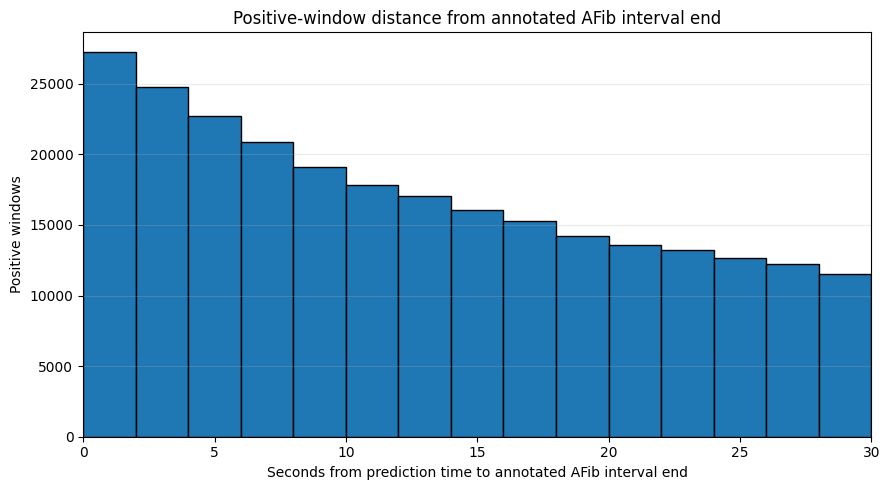

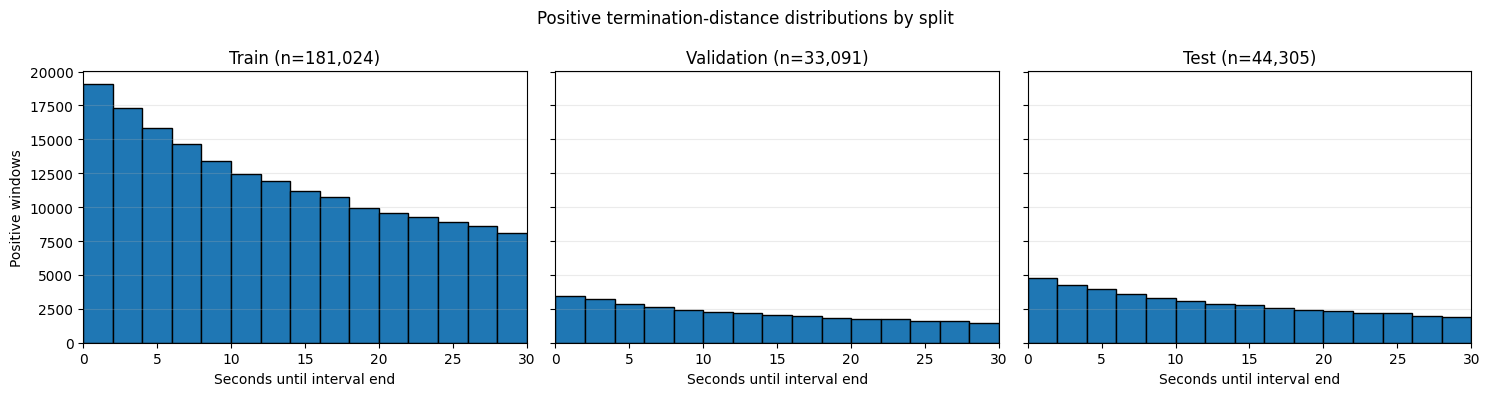

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/icentia11k_afib_audit")
OUT = ROOT / "pilot_10s_30s"

# Load existing candidate-window index
df = pd.read_csv(OUT / "candidate_window_index.csv")

# Keep positive windows
pos = df.loc[df["label"] == 1].copy()

# Use the already-calculated termination distance
pos["seconds_until_termination"] = pd.to_numeric(
    pos["seconds_until_annotated_end"], errors="coerce"
)

pos = pos.dropna(subset=["seconds_until_termination"])

print(f"Total positive windows: {len(pos):,}")
print(f"Unique positive AF episodes: {pos[['patient', 'record_stem', 'episode_id']].drop_duplicates().shape[0]:,}")
print(f"Unique patients: {pos['patient'].nunique():,}")

# Check whether positive labels are consistent with the 30-second horizon
print("\nTermination-distance sanity check:")
print(pos["seconds_until_termination"].describe())

print(
    "\nPositive windows outside (0, 30] seconds:",
    (
        (pos["seconds_until_termination"] <= 0)
        | (pos["seconds_until_termination"] > 30)
    ).sum()
)

# 5-second bins
bins = [0, 5, 10, 15, 20, 25, 30]
labels = ["0–5", ">5–10", ">10–15", ">15–20", ">20–25", ">25–30"]

pos["termination_bin"] = pd.cut(
    pos["seconds_until_termination"],
    bins=bins,
    labels=labels,
    right=True,
    include_lowest=False
)

print("\nPositive windows by time to termination:")
bin_counts = (
    pos["termination_bin"]
    .value_counts(sort=False)
    .rename("window_count")
    .to_frame()
)
bin_counts["percent"] = (
    bin_counts["window_count"] / len(pos) * 100
).round(2)
display(bin_counts)

# Breakdown by split
print("\nTermination-distance summary by split:")
display(
    pos.groupby("partition", observed=True)["seconds_until_termination"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

print("\nTermination-distance bins by split:")
split_bins = pd.crosstab(
    pos["termination_bin"],
    pos["partition"],
    dropna=False
)
display(split_bins)

# Plot 1: Overall distribution
plt.figure(figsize=(9, 5))
plt.hist(
    pos["seconds_until_termination"],
    bins=np.arange(0, 32, 2),
    edgecolor="black"
)
plt.xlabel("Seconds from prediction time to annotated AFib interval end")
plt.ylabel("Positive windows")
plt.title("Positive-window distance from annotated AFib interval end")
plt.xticks(np.arange(0, 31, 5))
plt.xlim(0, 30)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Plot 2: Compare splits
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, split in zip(axes, ["train", "validation", "test"]):
    values = pos.loc[
        pos["partition"] == split, "seconds_until_termination"
    ]
    ax.hist(
        values,
        bins=np.arange(0, 32, 2),
        edgecolor="black"
    )
    ax.set_title(f"{split.capitalize()} (n={len(values):,})")
    ax.set_xlabel("Seconds until interval end")
    ax.set_xlim(0, 30)
    ax.grid(axis="y", alpha=0.25)

axes[0].set_ylabel("Positive windows")
fig.suptitle("Positive termination-distance distributions by split")
plt.tight_layout()
plt.show()